In [25]:
import pandas as pd 
import numpy as np 
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [2]:
%pip install statsmodels scikit-learn seaborn matplotlib pandas numpy

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 4.8 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/11.3 MB 5.0 MB/s eta 0:00:02
   ---------- ----------------------------- 2.9/11.3 MB 4.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 4.7 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 4.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.3 MB 4.7 MB/s eta 0:00:02
   ------------------------ --------------- 6.8/11.3 MB 4.6 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 4.5 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 4.4 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 4.2 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 4.2 MB/s eta 0:00:01
   ------------------------------------- -- 10.5/11.3 MB 4.2 MB/s eta 0:00:01
   --


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Importing the Dataset

In [3]:
data = pd.read_csv('weather_months_data_120.csv')
data.head()

,Month,Data
0,January,21.9
1,February,24.5
2,March,28.1
3,April,30.8
4,May,31.4


Creating a date range

In [19]:
data = pd.read_csv('weather_months_data_120.csv')
dates = pd.date_range(start='2015-01-01', freq='MS', periods=len(data))
data.set_index(dates, inplace=True)
data.drop('Month', axis=1, inplace=True)

In [5]:
data.set_index(dates,inplace=True)
data.drop('Month',axis=1,inplace=True)

# Modeling

In [21]:
train = data[data.index < '2023-01-01']
test = data[data.index >= '2023-01-01']

# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [8]:
from statsmodels.tsa.ar_model import AutoReg
lags = 12
model = AutoReg(train, lags=lags)
model_fit = model.fit()

In [9]:
# Assuming you have already fitted the model (as shown in the previous code snippet)

# Get the number of lags considered statistically
lags_statistically = lags

# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const       6.065603
Data.L1     0.410128
Data.L2     0.168839
Data.L3    -0.128580
Data.L4    -0.203839
Data.L5    -0.071460
Data.L6     0.347558
Data.L7    -0.067755
Data.L8    -0.324203
Data.L9     0.098490
Data.L10    0.025757
Data.L11    0.410964
Data.L12    0.109005
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [10]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [11]:
print('The first test value in Sales :',test.values[1],'and its Predicted value : ',predictions.values[1])

The first test value in Sales : [23.5] and its Predicted value :  24.39225018696173


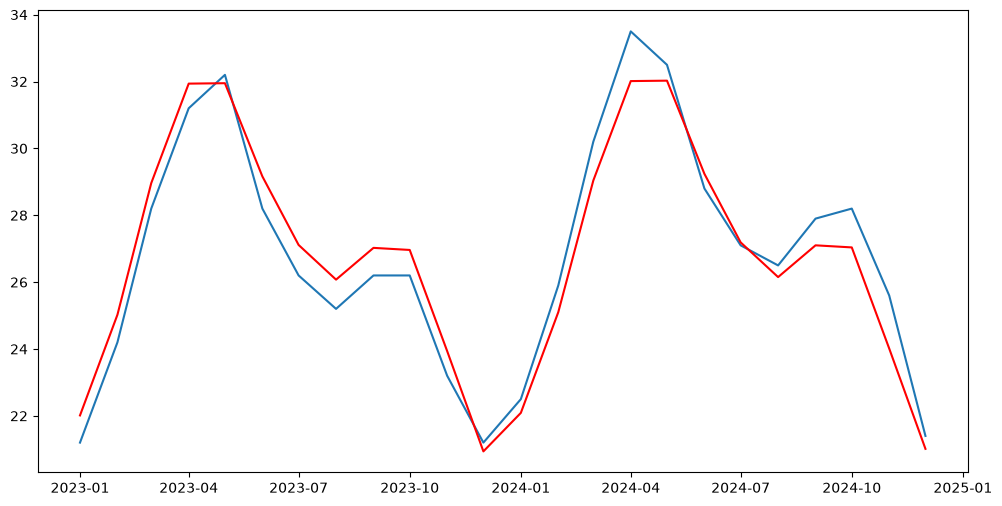

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

In [24]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Data'], predictions))
rmse = round(rmse, 3)

In [26]:
# Mean Absolute Percentage Error
abs_error = np.abs(test['Data']-predictions)
actual = test['Data']
mape = np.round(np.mean(abs_error/actual),3)
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'RMSE': [rmse]})
resultsDf
mape

np.float64(0.028)

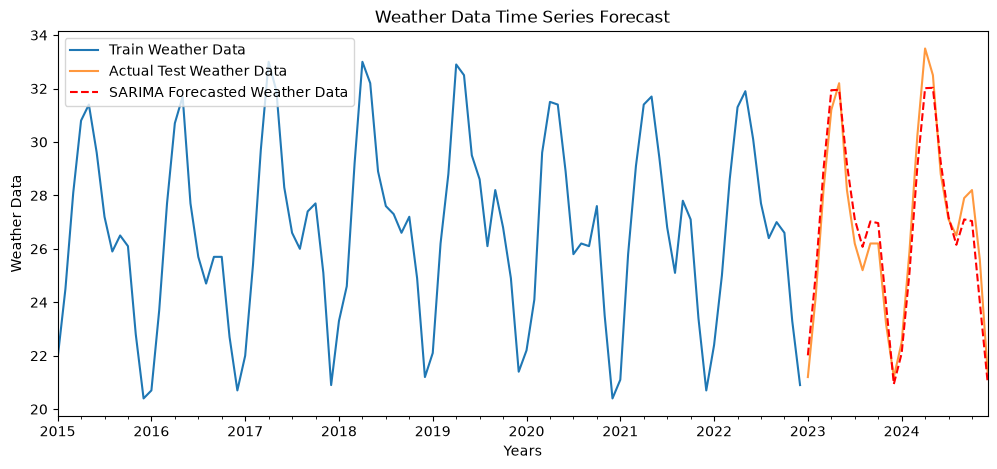

                           Method   RMSE   MAPE
0            Auto Regressive (AR)  1.108  0.034
1                 ARIMA (6, 0, 0)  2.175  0.062
2  SARIMA (0, 1, 1)x(0, 1, 1, 12)  0.829  0.028


In [16]:
import pandas as pd
import numpy as np
import itertools
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Load YOUR Weather Dataset (120 months = 10 years)
data = pd.read_csv('weather_months_data_120.csv')
dates = pd.date_range(start='2015-01-01', freq='MS', periods=len(data))
data.set_index(dates, inplace=True)
data.drop('Month', axis=1, inplace=True)

# Split: First 8 years (96 months) for Training, Last 2 years (24 months) for Testing
train = data.iloc[:96]
test = data.iloc[96:]

# 2. Model 1: Auto Regressive (AR)
model_ar = AutoReg(train['Data'], lags=12).fit()
pred_ar = model_ar.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
rmse_ar = round(np.sqrt(mean_squared_error(test['Data'], pred_ar)), 3)
mape_ar = np.round(np.mean(np.abs(test['Data'] - pred_ar) / test['Data']), 3)

# 3. Model 2: ARMA / ARIMA
pq = list(itertools.product(range(0, 7), range(0, 1)))
best_aic, best_pq = np.inf, None
for param in pq:
    try:
        res = ARIMA(train['Data'], order=(param[0], 0, param[1])).fit()
        if res.aic < best_aic:
            best_aic, best_pq = res.aic, param
    except:
        continue

model_arima = ARIMA(train['Data'], order=(best_pq[0], 0, best_pq[1])).fit()
pred_arima = model_arima.predict(start=len(train), end=len(train)+len(test)-1)
rmse_arima = round(np.sqrt(mean_squared_error(test['Data'], pred_arima)), 3)
mape_arima = np.round(np.mean(np.abs(test['Data'] - pred_arima) / test['Data']), 3)

# 4. Model 3: SARIMA (Seasonal period = 12 months)
pdq = list(itertools.product(range(0, 2), range(0, 2), range(0, 2)))
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in pdq]
best_aic_s, best_pdq, best_spdq = np.inf, None, None
for param in pdq:
    for sparam in seasonal_pdq:
        try:
            res = SARIMAX(train['Data'], order=param, seasonal_order=sparam,
                          enforce_invertibility=False, enforce_stationarity=False).fit(disp=False)
            if res.aic < best_aic_s:
                best_aic_s, best_pdq, best_spdq = res.aic, param, sparam
        except:
            continue

model_sarima = SARIMAX(train['Data'], order=best_pdq, seasonal_order=best_spdq,
                       enforce_invertibility=False, enforce_stationarity=False).fit(disp=False)
pred_sarima = model_sarima.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
rmse_sarima = round(np.sqrt(mean_squared_error(test['Data'], pred_sarima)), 3)
mape_sarima = np.round(np.mean(np.abs(test['Data'] - pred_sarima) / test['Data']), 3)

# 5. Plot Forecast & Print Final Results Table
axis = train['Data'].plot(label='Train Weather Data', figsize=(12, 5))
test['Data'].plot(ax=axis, label='Actual Test Weather Data', alpha=0.8)
pred_sarima.plot(ax=axis, label='SARIMA Forecasted Weather Data', color='red', linestyle='--')
axis.set_xlabel('Years')
axis.set_ylabel('Weather Data')
plt.title('Weather Data Time Series Forecast')
plt.legend(loc='best')
plt.show()

resultsDf = pd.DataFrame({
    'Method': ['Auto Regressive (AR)', f'ARIMA {best_pq+(0,)}', f'SARIMA {best_pdq}x{best_spdq}'],
    'RMSE': [rmse_ar, rmse_arima, rmse_sarima],
    'MAPE': [mape_ar, mape_arima, mape_sarima]
})
print(resultsDf)

In [13]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'MAPE': [mape], 'RMSE': [rmse]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,1379.475,0.208


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

--- First 5 Rows of YOUR Weather Dataset ---
      Month  Data
0   January  21.9
1  February  24.5
2     March  28.1
3     April  30.8
4       May  31.4


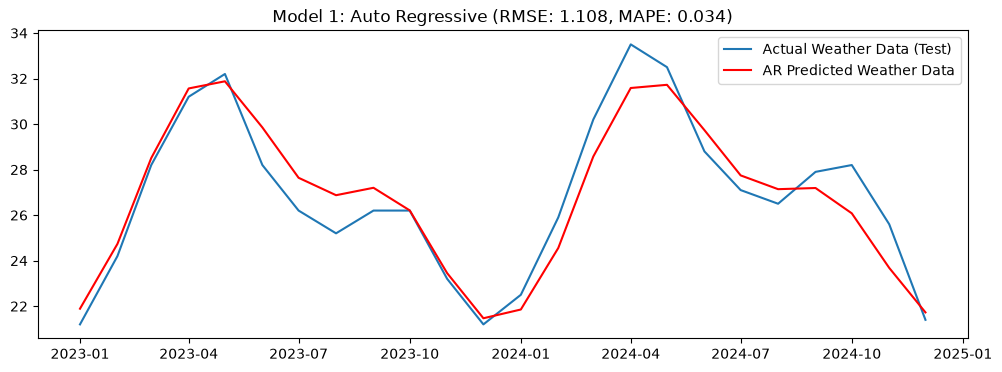

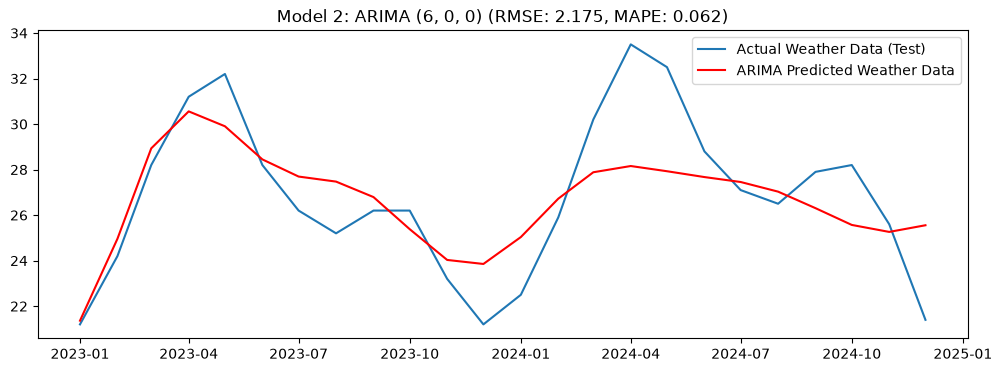

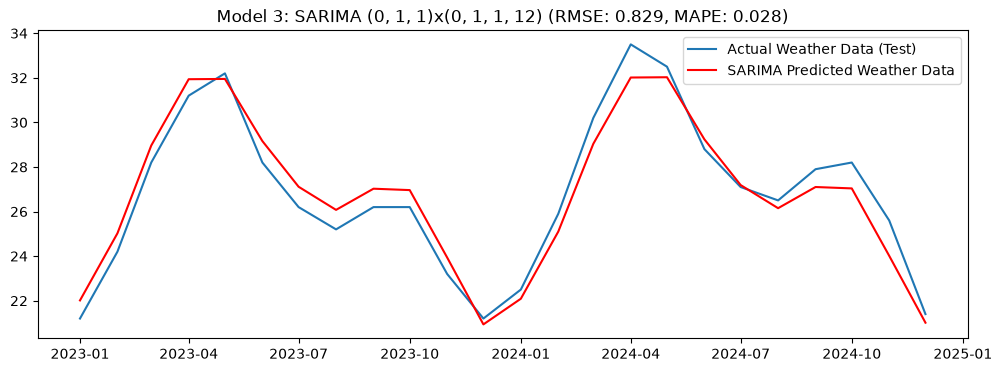

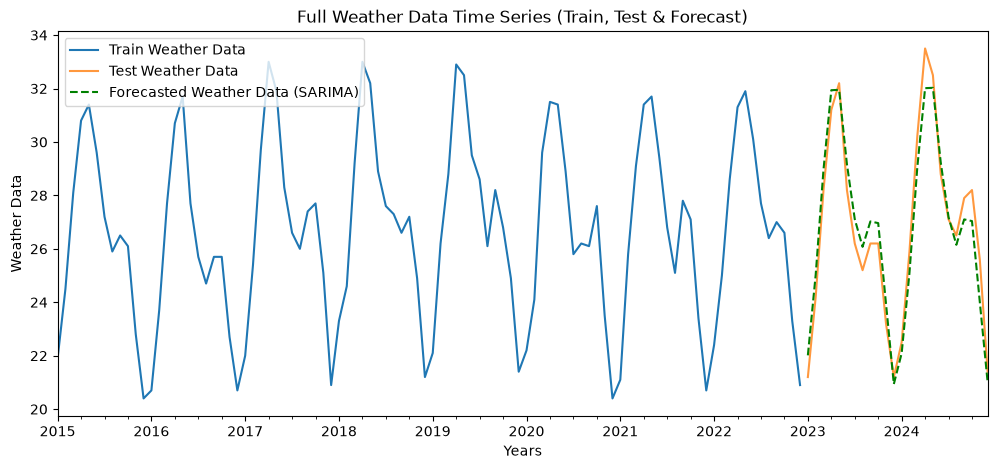


--- FINAL WEATHER DATASET RESULTS ---
                                              Method   RMSE   MAPE
0                                    Auto Regressive  1.108  0.034
1                     Auto Regressive Moving Average  2.175  0.062
2  Seasonal Autoregressive Integrated Moving Average  0.829  0.028


In [17]:
import pandas as pd
import numpy as np
import itertools
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Load YOUR Weather Dataset (Values are between 20.4 and 33.5)
data = pd.read_csv('weather_months_data_120.csv')
print("--- First 5 Rows of YOUR Weather Dataset ---")
print(data.head())

dates = pd.date_range(start='2015-01-01', freq='MS', periods=len(data))
data.set_index(dates, inplace=True)
data.drop('Month', axis=1, inplace=True)

# Train (first 96 months) and Test (last 24 months)
train = data.iloc[:96]
test = data.iloc[96:]

# ==========================================
# MODEL 1: Auto Regressive (AR)
# ==========================================
model_ar = AutoReg(train['Data'], lags=12).fit()
pred_ar = model_ar.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
rmse_ar = round(np.sqrt(mean_squared_error(test['Data'], pred_ar)), 3)
mape_ar = np.round(np.mean(np.abs(test['Data'] - pred_ar) / test['Data']), 3)

plt.figure(figsize=(12, 4))
plt.plot(test['Data'], label='Actual Weather Data (Test)')
plt.plot(pred_ar, color='red', label='AR Predicted Weather Data')
plt.title(f'Model 1: Auto Regressive (RMSE: {rmse_ar}, MAPE: {mape_ar})')
plt.legend()
plt.show()

# ==========================================
# MODEL 2: ARMA / ARIMA
# ==========================================
pq = list(itertools.product(range(0, 7), range(0, 1)))
best_aic, best_pq = np.inf, None
for param in pq:
    try:
        res = ARIMA(train['Data'], order=(param[0], 0, param[1])).fit()
        if res.aic < best_aic:
            best_aic, best_pq = res.aic, param
    except:
        continue

model_arima = ARIMA(train['Data'], order=(best_pq[0], 0, best_pq[1])).fit()
pred_arima = model_arima.predict(start=len(train), end=len(train)+len(test)-1)
rmse_arima = round(np.sqrt(mean_squared_error(test['Data'], pred_arima)), 3)
mape_arima = np.round(np.mean(np.abs(test['Data'] - pred_arima) / test['Data']), 3)

plt.figure(figsize=(12, 4))
plt.plot(test['Data'], label='Actual Weather Data (Test)')
plt.plot(pred_arima, color='red', label='ARIMA Predicted Weather Data')
plt.title(f'Model 2: ARIMA {best_pq+(0,)} (RMSE: {rmse_arima}, MAPE: {mape_arima})')
plt.legend()
plt.show()

# ==========================================
# MODEL 3: SARIMA
# ==========================================
pdq = list(itertools.product(range(0, 2), range(0, 2), range(0, 2)))
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in pdq]
best_aic_s, best_pdq, best_spdq = np.inf, None, None
for param in pdq:
    for sparam in seasonal_pdq:
        try:
            res = SARIMAX(train['Data'], order=param, seasonal_order=sparam,
                          enforce_invertibility=False, enforce_stationarity=False).fit(disp=False)
            if res.aic < best_aic_s:
                best_aic_s, best_pdq, best_spdq = res.aic, param, sparam
        except:
            continue

model_sarima = SARIMAX(train['Data'], order=best_pdq, seasonal_order=best_spdq,
                       enforce_invertibility=False, enforce_stationarity=False).fit(disp=False)
pred_sarima = model_sarima.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
rmse_sarima = round(np.sqrt(mean_squared_error(test['Data'], pred_sarima)), 3)
mape_sarima = np.round(np.mean(np.abs(test['Data'] - pred_sarima) / test['Data']), 3)

plt.figure(figsize=(12, 4))
plt.plot(test['Data'], label='Actual Weather Data (Test)')
plt.plot(pred_sarima, color='red', label='SARIMA Predicted Weather Data')
plt.title(f'Model 3: SARIMA {best_pdq}x{best_spdq} (RMSE: {rmse_sarima}, MAPE: {mape_sarima})')
plt.legend()
plt.show()

# ==========================================
# FULL FORECAST PLOT & FINAL TABLE
# ==========================================
axis = train['Data'].plot(label='Train Weather Data', figsize=(12, 5))
test['Data'].plot(ax=axis, label='Test Weather Data', alpha=0.8)
pred_sarima.plot(ax=axis, label='Forecasted Weather Data (SARIMA)', color='green', linestyle='--')
axis.set_xlabel('Years')
axis.set_ylabel('Weather Data')
plt.title('Full Weather Data Time Series (Train, Test & Forecast)')
plt.legend(loc='best')
plt.show()

resultsDf = pd.DataFrame({
    'Method': ['Auto Regressive', 'Auto Regressive Moving Average', 'Seasonal Autoregressive Integrated Moving Average'],
    'RMSE': [rmse_ar, rmse_arima, rmse_sarima],
    'MAPE': [mape_ar, mape_arima, mape_sarima]
})
print("\n--- FINAL WEATHER DATASET RESULTS ---")
print(resultsDf)

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level. 

Best SARIMA (0, 1, 1) x (0, 1, 1, 12) model - AIC:163.5706555916356


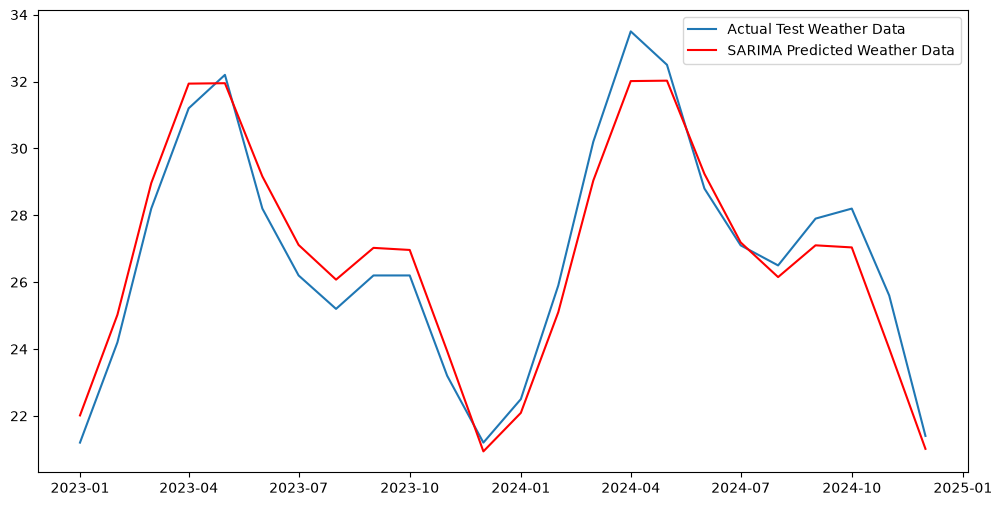

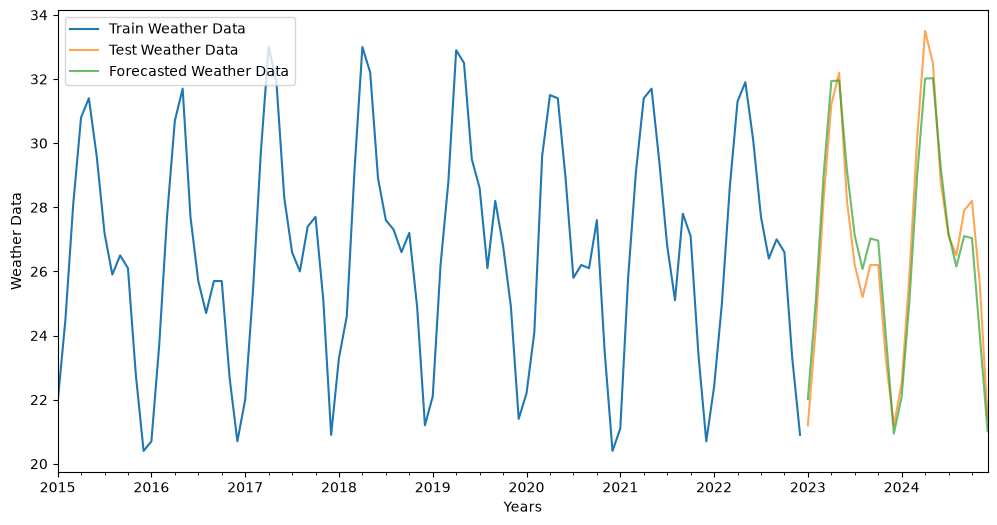

In [18]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, d and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:   
    for param_seasonal in seasonal_pdq: 
        try:
            temp_model = SARIMAX(train['Data'], order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# Using the best parameter in the model
model = SARIMAX(train['Data'], order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit(disp=False)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(test['Data'], label='Actual Test Weather Data')
plt.plot(predictions, color='red', label='SARIMA Predicted Weather Data')
plt.legend()
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Data'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error (MAPE)
abs_error = np.abs(test['Data'] - predictions)
actual = test['Data']
mape = np.round(np.mean(abs_error / actual), 3)

# Plotting the train, test and forecasted weather data
axis = train['Data'].plot(label='Train Weather Data', figsize=(12, 6))
test['Data'].plot(ax=axis, label='Test Weather Data', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted Weather Data', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Weather Data')
plt.legend(loc='best')
plt.show()
plt.close()

In [16]:
# Storing results in a dataframe

print(resultsDf)

                                              Method      RMSE   MAPE
0                                    Auto Regressive  1379.475  0.208
1                    Auto Regressive Moving average   3186.469  0.383
2  Seasonal Autoregressive Integrated Moving Average  1035.182  0.235
